# Experiments for the functional distortion maps paper

We check the recovered maps against the exact torus–line distance, reproduce the factor-three case, and compare traversal schedules on the A/B pair. The same maps are used to compare pruned and exhaustive evaluation.

All scores are in grid units with $\delta=1$. Evaluations use exact fractions, and only the displays round the scores. The saved runs use single-threaded CBC with fixed seeds and `PYTHONHASHSEED=0`.

In [1]:
import sys
from fractions import Fraction
from importlib.metadata import version
from pathlib import Path
from statistics import median
from time import perf_counter

import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from cereeberus import Interleave
from cereeberus.data import ex_mappergraphs as ex
from pulp import PULP_CBC_CMD

if Path.cwd().name == "experiments":
    sys.path.insert(0, str(Path.cwd().parent))

from core.distortion import functional_distortion, graph_distance
from core.fd_map_build import maps_from_interleave
from core.functionaldistortiongraph import FunctionalDistortionGraph, V
from visualize.fd_metromaps import draw_fd_maps, set_integer_ticks

print(f"ceREEBerus {version('cereeberus')} · PuLP {version('pulp')}")


def fit_maps(F, G):
    """Find the smallest feasible grid parameter and recover maps once."""
    interleaving = Interleave(F, G)
    solver = PULP_CBC_CMD(msg=False, threads=1, options=["randomSeed 1", "randomCbcSeed 1"])
    n = interleaving.fit(pulp_solver=solver)
    return n, maps_from_interleave(interleaving, seed=0)


def map_arguments(maps):
    """Return the two realizations and maps in evaluator order."""
    return maps["F"], maps["G"], maps["Phi"], maps["Psi"]


ceREEBerus 0.2.0 · PuLP 3.3.2


## Torus and line

For each integer loop height $h$ from $2$ to $12$, we fit one interleaving and compare the recovered FD with the exact distance $h/4$.

Recovered FD matches h/4 at 11 of 11 heights.


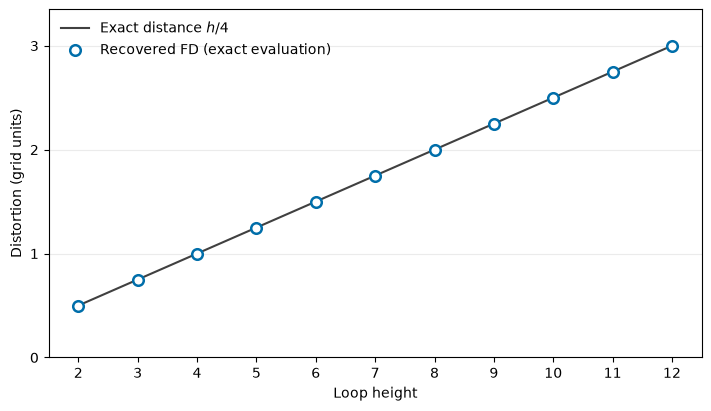

In [2]:
heights = range(2, 13)
recovered_fd = []

for h in heights:
    n, maps = fit_maps(
        ex.torus(0, 1, h + 1, h + 2, delta=1, seed=0),
        ex.line(0, h + 2, seed=0),
    )
    scores = functional_distortion(*map_arguments(maps), decimals=None)
    recovered_fd.append(scores["FD_units"])
    assert scores["height_Phi_units"] == scores["height_Psi_units"] == 0
    if h == 3:
        torus_n, torus_maps = n, maps

exact_distances = [Fraction(h, 4) for h in heights]
print(f"Recovered FD matches h/4 at {sum(a == b for a, b in zip(recovered_fd, exact_distances))}"
      f" of {len(heights)} heights.")

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.plot(heights, exact_distances, color="0.25", label=r"Exact distance $h/4$")
ax.scatter(heights, recovered_fd, facecolors="white", edgecolors="#006eaa", s=58,
           linewidths=1.8, label="Recovered FD (exact evaluation)", zorder=3)
ax.set(xlabel="Loop height", ylabel="Distortion (grid units)", ylim=(0, 3.35))
set_integer_ticks(ax)
ax.set_axisbelow(True)
ax.grid(axis="y", color="0.92")
ax.legend(loc="upper left", frameon=False)
plt.show()


**Why $h/4$ is a lower bound on the optimal distance.** Any continuous map from the loop to the line identifies two antipodal points. Their height-range distance on the loop is at least $h/2$, so every map pair has $D\geq h/4$. The recovered maps attain this bound. The general grid lower bound $(d_I-1)\delta$ is weaker here. For $h=3$, the optimal grid parameter is $d_I=1$ and $\delta=1$, so that bound gives $0$.

## Pruned and exhaustive evaluation

We compare the two evaluators on the same Fréchet maps and check that they give identical exact $D$ and FD. Times are medians of three runs per evaluator, alternating their order after building the shared graph-distance caches. Times include pruning overhead and exclude the ILP, map recovery, and the shared caches.

In [3]:
def factor_three_pair(T=9):
    """Build the factor-three pair with tails truncated at ±T."""
    def graph(intervals, joins):
        heights, edges = {}, []
        for branch, lo, hi in intervals:
            path = [joins.get((branch, level), (branch, level)) for level in range(lo, hi + 1)]
            heights.update((vertex, vertex[1]) for vertex in path)
            edges.extend(zip(path, path[1:]))
        return FunctionalDistortionGraph.from_edges(heights, edges).mapper

    F = graph(
        [("F1", 1, T), ("F2", 1, 3), ("F3", -T, T), ("F4", -T, -1), ("F5", -3, -1)],
        {("F2", 1): ("F1", 1), ("F2", 3): ("F3", 3),
         ("F5", -1): ("F4", -1), ("F5", -3): ("F3", -3)},
    )
    G = graph(
        [("G1", 0, T), ("G2", -T, T), ("G3", -T, 0)],
        {("G1", 0): ("G2", 0), ("G3", 0): ("G2", 0)},
    )
    return F, G


tight_n, tight_maps = fit_maps(*factor_three_pair())
ab_n, ab_maps = fit_maps(ex.interleave_example_A(seed=0), ex.interleave_example_B(seed=0))


In [4]:
def benchmark(maps):
    """Return exact scores and the median time in milliseconds for each evaluator."""
    F, G, Phi, Psi = map_arguments(maps)
    for graph in (F, G):
        point = V(next(iter(graph.f)))
        graph_distance(graph, point, point)

    results = {}
    times = {True: [], False: []}
    for order in ((True, False), (False, True), (True, False)):
        for prune in order:
            start = perf_counter()
            result = functional_distortion(F, G, Phi, Psi, prune=prune,
                                           exact_D=True, decimals=None)
            times[prune].append(1_000 * (perf_counter() - start))
            results[prune] = result
        pruned, exhaustive = results[True], results[False]
        assert pruned["D_exact"]
        assert pruned["D_units"] == exhaustive["D_units"]
        assert pruned["FD_units"] == exhaustive["FD_units"]
        assert pruned["pairs_total"] == exhaustive["pairs_total"]

    return results[True], median(times[True]), median(times[False])


rows = [
    "| Pair | n | Height errors Φ, Ψ | D | FD | Pairs visited | Pruned / exhaustive (ms) | Speedup |",
    "|---|---:|---:|---:|---:|---:|---:|---:|",
]
pruned_results = {}
for name, n, maps in (
    ("Torus–line, h = 3", torus_n, torus_maps),
    ("Factor-three pair", tight_n, tight_maps),
    ("A/B, Fréchet", ab_n, ab_maps),
):
    result, pruned_ms, exhaustive_ms = benchmark(maps)
    pruned_results[name] = result
    visited, total = result["pairs_visited"], result["pairs_total"]
    rows.append(
        f"| {name} | {n} | {float(result['height_Phi_units']):.3f}, "
        f"{float(result['height_Psi_units']):.3f} | {float(result['D_units']):.3f} | "
        f"{float(result['FD_units']):.3f} | {visited}/{total} ({visited / total:.1%}) | "
        f"{pruned_ms:.1f} / {exhaustive_ms:.1f} | {exhaustive_ms / pruned_ms:.2f}× |"
    )
display(Markdown("\n".join(rows)))


| Pair | n | Height errors Φ, Ψ | D | FD | Pairs visited | Pruned / exhaustive (ms) | Speedup |
|---|---:|---:|---:|---:|---:|---:|---:|
| Torus–line, h = 3 | 1 | 0.000, 0.000 | 0.750 | 0.750 | 10/91 (11.0%) | 4.1 / 24.4 | 5.94× |
| Factor-three pair | 1 | 1.000, 1.000 | 3.000 | 3.000 | 104/3741 (2.8%) | 50.6 / 1464.6 | 28.96× |
| A/B, Fréchet | 4 | 4.000, 2.000 | 3.500 | 4.000 | 3003/3003 (100.0%) | 1343.1 / 1285.3 | 0.96× |

Pruning saves time when the pairs it skips outweigh the cost of computing the round-trip errors and sorting the pieces. A pair is skipped once its upper bound on the distance discrepancy is at most twice the best $D$ found so far. Small height and round-trip errors make those upper bounds tighter, and finding a large witness early raises the cutoff.

Every pair bound is at least twice the larger height error. On A/B that error exceeds the exact $D$, so the evaluator visits every pair. The torus–line and factor-three examples skip most pairs.

## A/B scheduling and correspondence

Fix the vertex images and routes from one ILP fit. Uniform timing divides the source edge equally among the route pieces. Fréchet timing uses the schedule from map recovery. The figure shows the Fréchet maps, with $\Phi\colon A\to B$ in the top row and $\Psi\colon B\to A$ in the bottom row.

In [5]:
def uniform_map(mapping):
    """Retain the map's route points and use equal times for its pieces."""
    routes = {edge: [piece[3] for piece in pieces[:-1]]
              for edge, pieces in mapping["segments"].items()}
    return mapping["source"].map_to(mapping["target"], mapping["vertex_image"], routes)


uniform_maps = {
    **ab_maps,
    "Phi": uniform_map(ab_maps["Phi"]),
    "Psi": uniform_map(ab_maps["Psi"]),
}
for name in ("Phi", "Psi"):
    original, uniform = ab_maps[name], uniform_maps[name]
    assert original["vertex_image"] == uniform["vertex_image"]
    for edge, pieces in original["segments"].items():
        assert [p[2:] for p in pieces] == [p[2:] for p in uniform["segments"][edge]]

uniform_scores = functional_distortion(*map_arguments(uniform_maps), prune=False, decimals=None)
frechet_scores = pruned_results["A/B, Fréchet"]
for label, scores in (("Uniform", uniform_scores), ("Fréchet", frechet_scores)):
    print(
        f"{label}: height errors {float(scores['height_Phi_units']):.3f}, "
        f"{float(scores['height_Psi_units']):.3f}; "
        f"D = {float(scores['D_units']):.3f}; FD = {float(scores['FD_units']):.3f}"
    )


Uniform: height errors 4.500, 2.400; D = 3.500; FD = 4.500
Fréchet: height errors 4.000, 2.000; D = 3.500; FD = 4.000


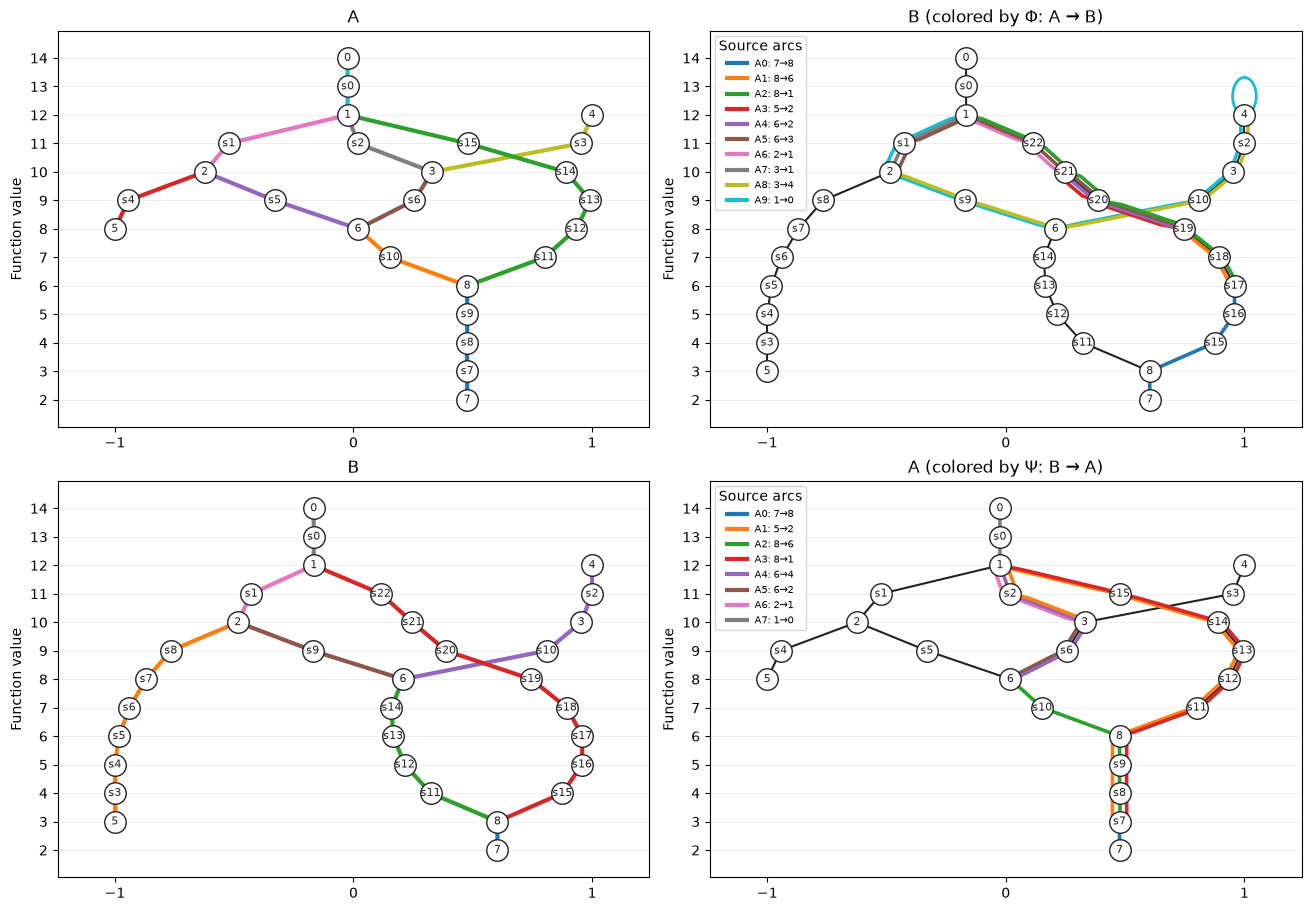

In [6]:
draw_fd_maps(
    ab_maps["Phi"], ab_maps["Psi"], names=("A", "B"),
    show_vertmaps=False, show_breakpoints=False, figsize=(13, 9),
)
plt.show()
